# 4.3.0 Neighbourhood and Niche analysis

**Inés Sentís** 

In [1]:
from pyprojroot import here
here = str(here())
import sys, os
sys.path.append(os.path.join(here,"utils"))

In [2]:
# basic pkgs
import os
import pandas as pd
import numpy as np
import glob

# analysis pkgs
import scanpy as sc
import anndata as ad
from scipy.stats import entropy
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
 
# plotting pkgs
import matplotlib.pyplot as plt
from matplotlib import rcParams
import seaborn as sns

# own modules
from paths import *
from variables import colors_donors

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', -1)

%load_ext autoreload
%autoreload 2
%config IPCompleter.greedy=True

/scratch_tmp/53060597/ipykernel_235107/33722656.py:26: FutureWarning: Passing a negative integer is deprecated in version 1.0 and will not be supported in future version. Instead, use None to not limit the column width.
  pd.set_option('display.max_colwidth', -1)


In [3]:
sc.logging.print_versions()
sc.set_figure_params(facecolor="white", figsize=(8, 8), 
                     scanpy=True, fontsize=16)
path_to_figures = os.path.join(here, "AVGUSTINOVA_01_06_09_15", "4-annotation", version, "plots_"+version)
sc.settings.figdir = path_to_figures
sc.settings.verbosity = 3

-----
anndata     0.9.2
scanpy      1.9.5
-----
PIL                         10.0.0
anyio                       NA
arrow                       1.2.3
asttokens                   NA
attr                        23.1.0
attrs                       23.1.0
babel                       2.12.1
backcall                    0.2.0
brotli                      1.1.0
certifi                     2023.07.22
cffi                        1.14.6
charset_normalizer          3.2.0
comm                        0.1.4
cycler                      0.10.0
cython_runtime              NA
dateutil                    2.8.2
debugpy                     1.8.0
decorator                   5.1.1
defusedxml                  0.7.1
exceptiongroup              1.1.3
executing                   1.2.0
fastjsonschema              NA
fqdn                        NA
h5py                        3.9.0
idna                        3.4
igraph                      0.11.8
importlib_resources         NA
ipykernel                   6.25.2
isodura

In [4]:
def config_rcparams():
    commonFontsize = 12
    plt.rcParams['font.family'] = ['sans-serif']
    plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
    plt.rcParams['font.size'] = commonFontsize
    plt.rcParams['axes.labelsize'] = commonFontsize
    plt.rcParams['xtick.labelsize'] = commonFontsize
    plt.rcParams['ytick.labelsize'] = commonFontsize
    plt.rcParams['axes.titlesize'] = 14
    # plt.rcParams['text'] = commonFontsize
    plt.rcParams['svg.fonttype'] = 'none'
    plt.rcParams['mathtext.fontset'] = 'custom'
    plt.rcParams['mathtext.cal'] = 'DejaVu Sans'
    plt.rcParams['mathtext.rm'] = 'DejaVu Sans'
    plt.rcParams['axes.edgecolor'] = 'black'
    plt.rcParams['ytick.color'] = 'black'
    plt.rcParams['axes.linewidth'] = 0.7
    plt.rcParams['xtick.major.width'] = 0.7
    plt.rcParams['ytick.major.width'] = 0.7
    plt.rcParams['xtick.major.size'] = 3
    plt.rcParams['ytick.major.size'] = 3
    


config_rcparams()

In [5]:
# Shannon entropy function
def compute_shannon_entropy(adata, radius=100):
    coords = adata.obsm["spatial"]
    props = adata.obsm["X_deconv"]
    if isinstance(props, pd.DataFrame):
        props = props.to_numpy()

    nn = NearestNeighbors(radius=radius)
    nn.fit(coords)
    neighborhoods = nn.radius_neighbors(coords, return_distance=False)

    neigh_props = []
    for idxs in neighborhoods:
        if len(idxs) == 0:
            neigh_props.append(np.zeros(props.shape[1]))
        else:
            avg_prop = props[idxs].mean(axis=0)
            neigh_props.append(avg_prop)

    neigh_props = np.array(neigh_props)
    eps = 1e-10
    shannon_entropy = entropy(neigh_props + eps, base=2, axis=1)

    adata.obs["shannon_entropy"] = shannon_entropy
    return adata

In [6]:
df_info = pd.read_csv(os.path.join(here, "utils/info_samples.csv"))
df_info = df_info[(df_info["modality"] == "st") & (~df_info["quality"].isin(["Bad", "NM"]))] 

In [7]:
dict_samples = dict()

for sample in df_info['patient']:
    print(sample)
    
    batch = df_info[df_info['patient'] == sample].reset_index()["subproject"][0]
    exec(open(os.path.join(here, batch,"st_analysis/misc/paths.py")).read())
    path_to_data = os.path.join(here, batch, "st_analysis/3-clustering", version, "py_objects_"+version)
    
    # read object
    adata = sc.read_h5ad(os.path.join(path_to_data, sample+'.h5ad'))

   # add it to the dict
    dict_samples[sample] = adata

p11
p10
p5
p8
p4
p9
p7
p2
p6
p13
p14


In [8]:
del dict_samples['p11']

### Compute score

**Shannon entropy** = _how mixed each neighborhood is_. The Shannon entropy quantifies the diversity (or uncertainty) of cell-type composition in a spot’s neighborhood.


| Metric              | Meaning                                                   | Low values                            | High values                             |
| :------------------ | :-------------------------------------------------------- | :------------------------------------ | :-------------------------------------- |
| **Shannon entropy** | Local diversity of cell types                             | Homogeneous (one cell type dominates) | Heterogeneous mixture                   |

p10


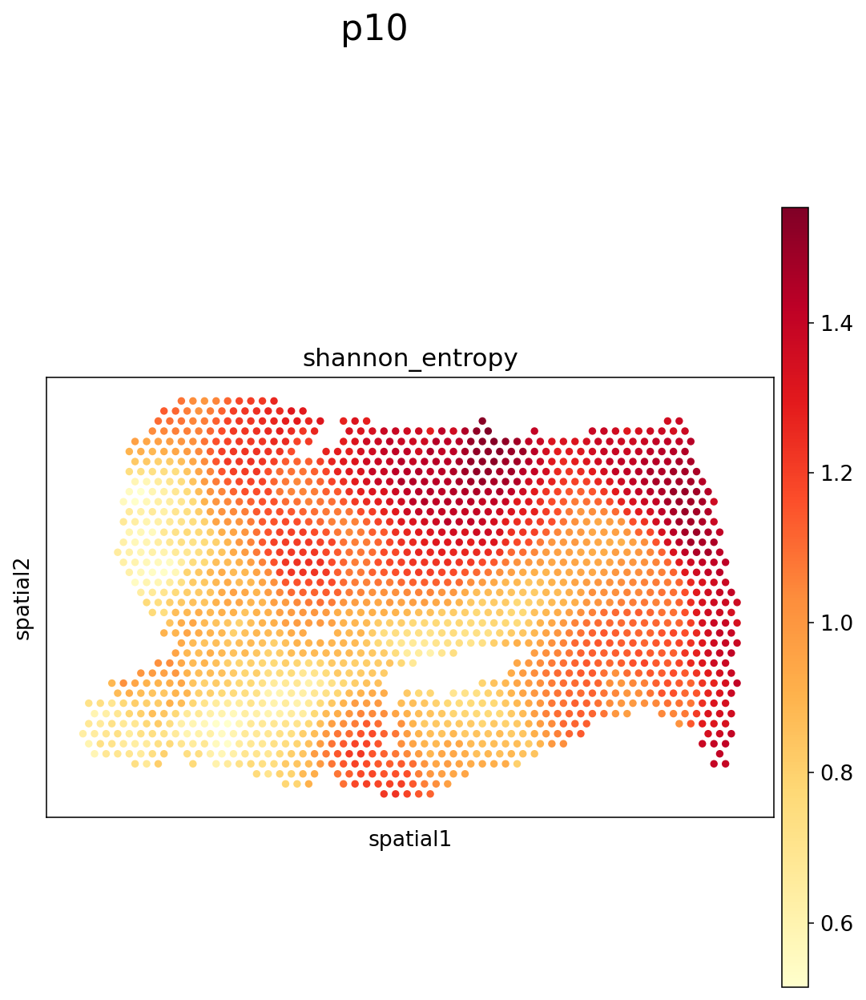

p5


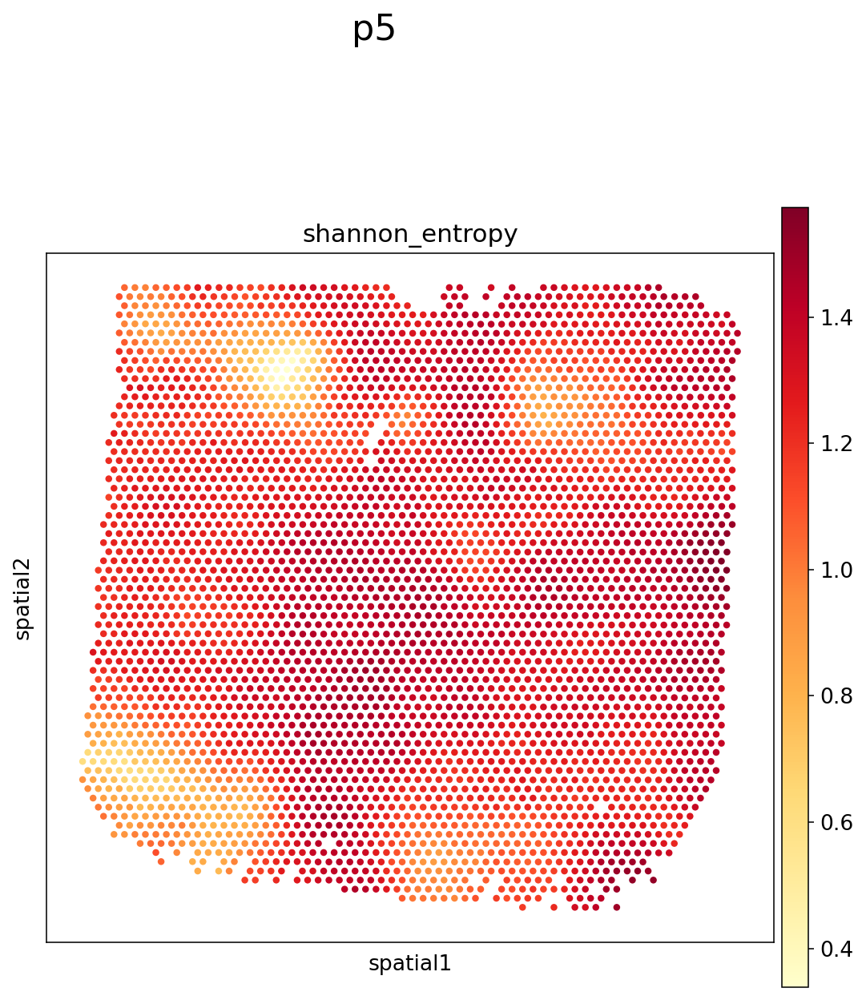

p8


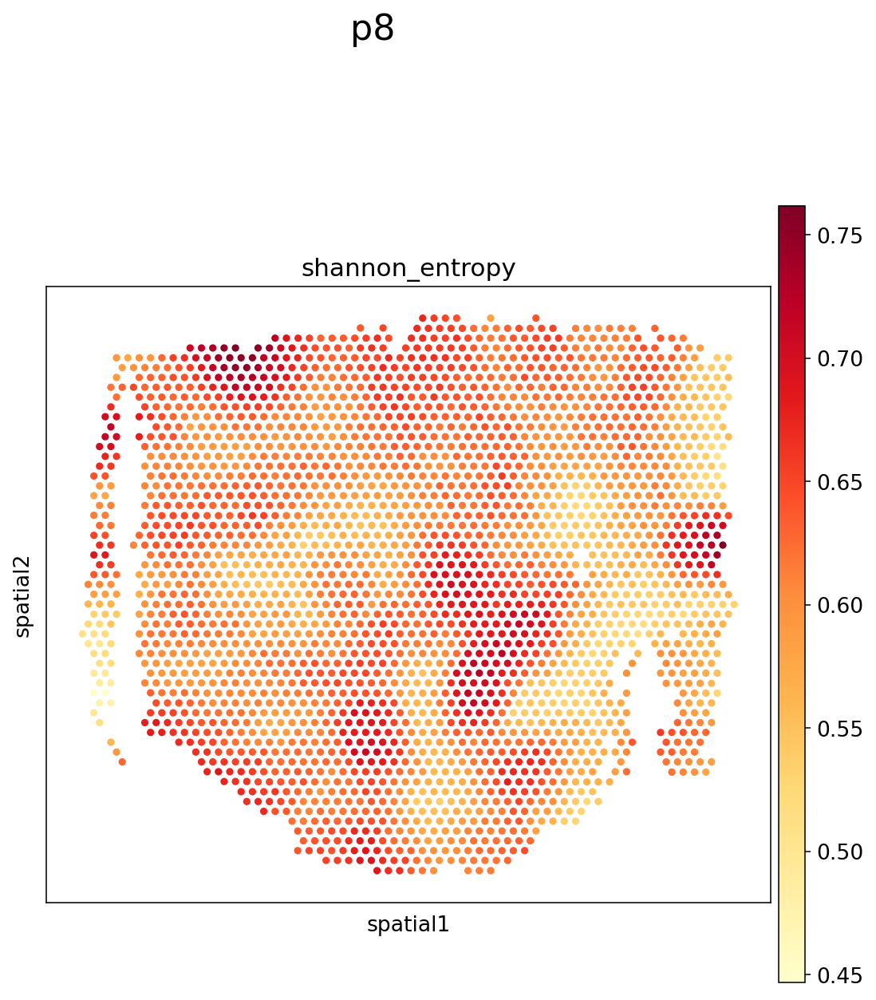

p4


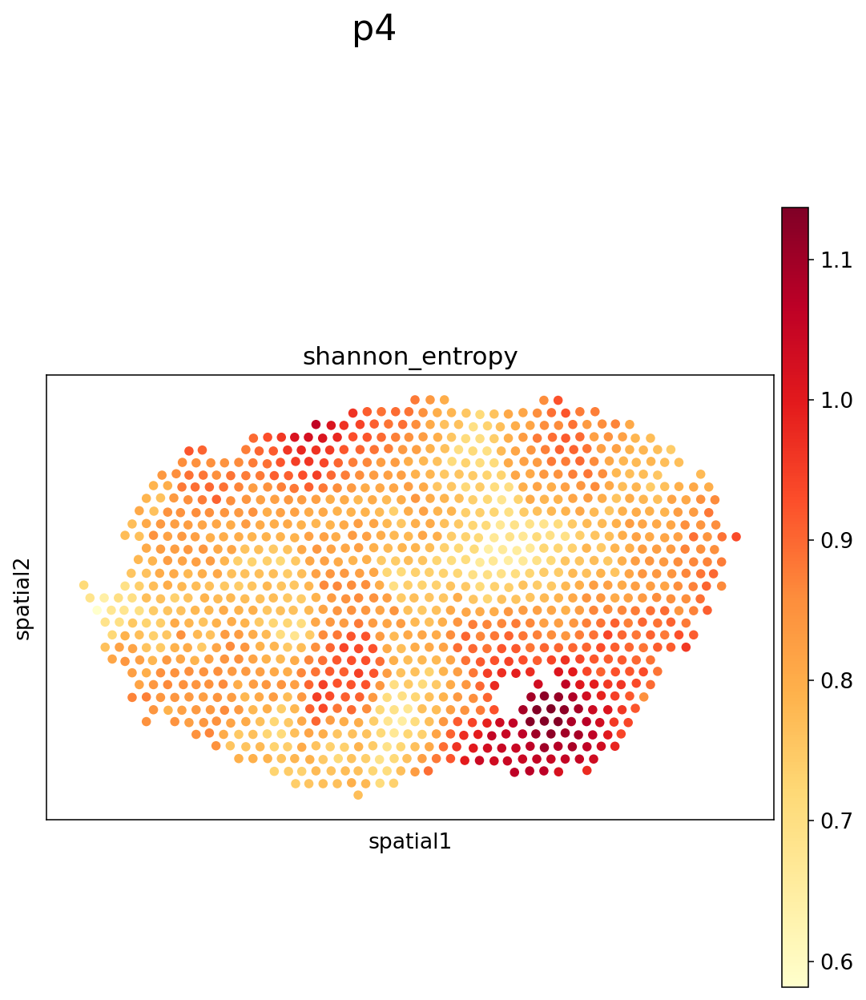

p9


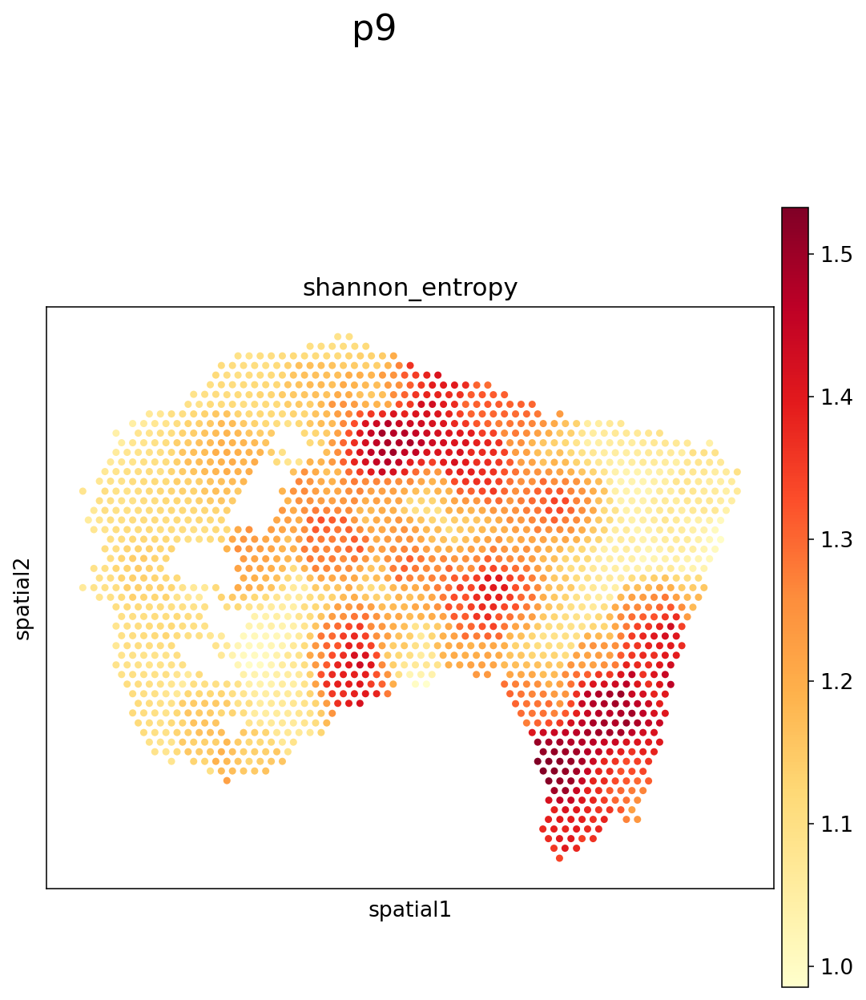

p7


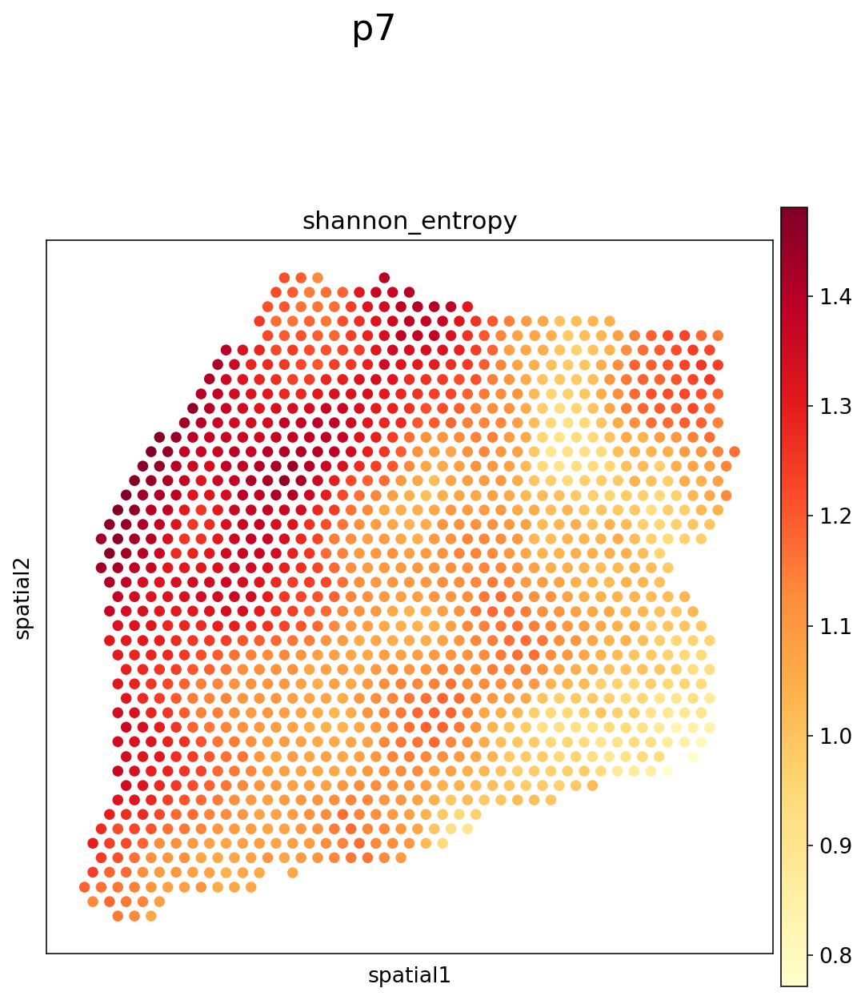

p2


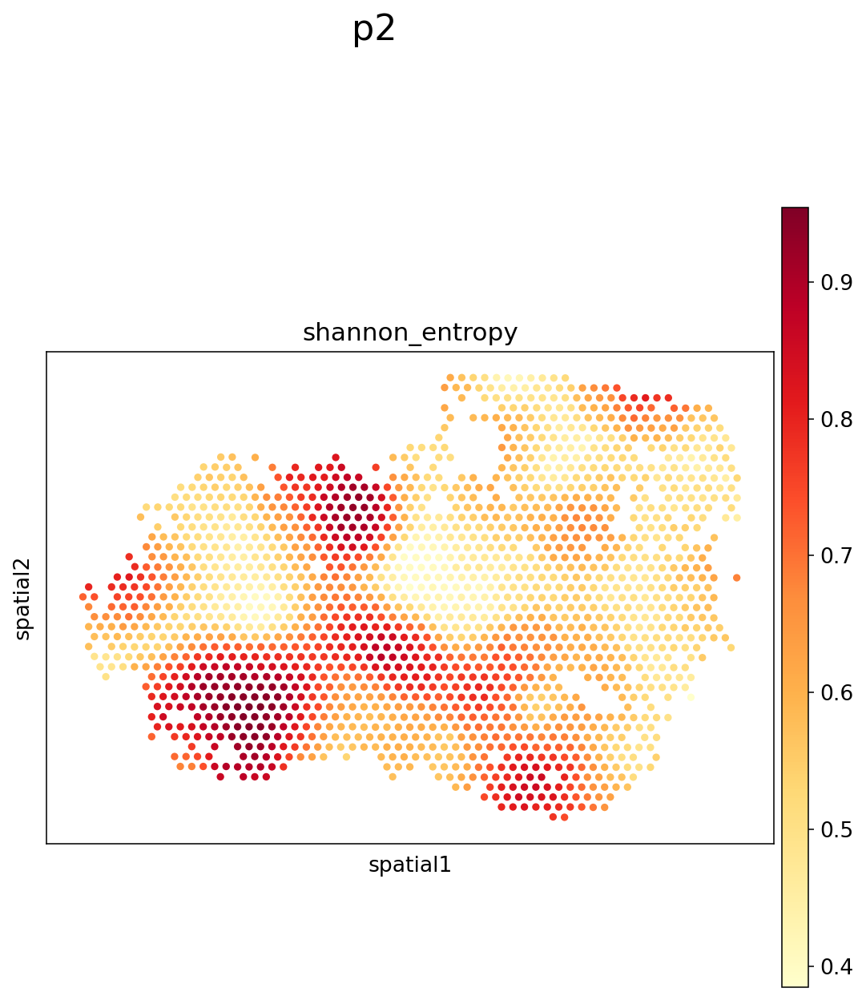

p6


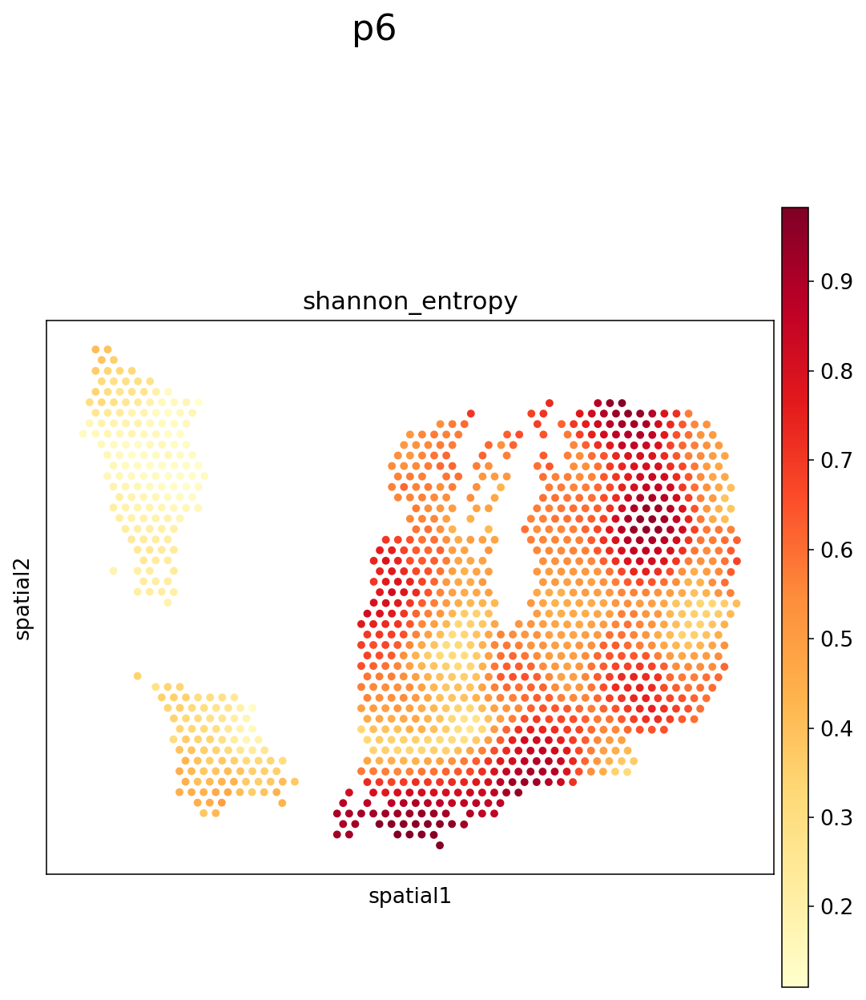

p13


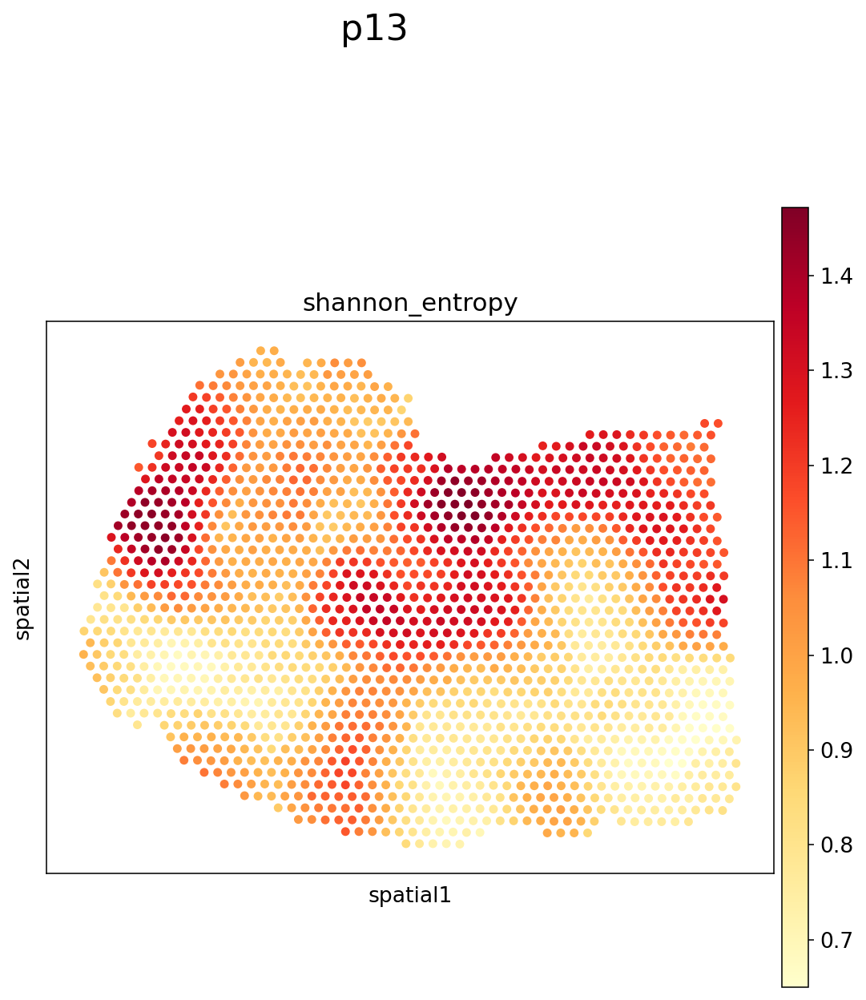

p14


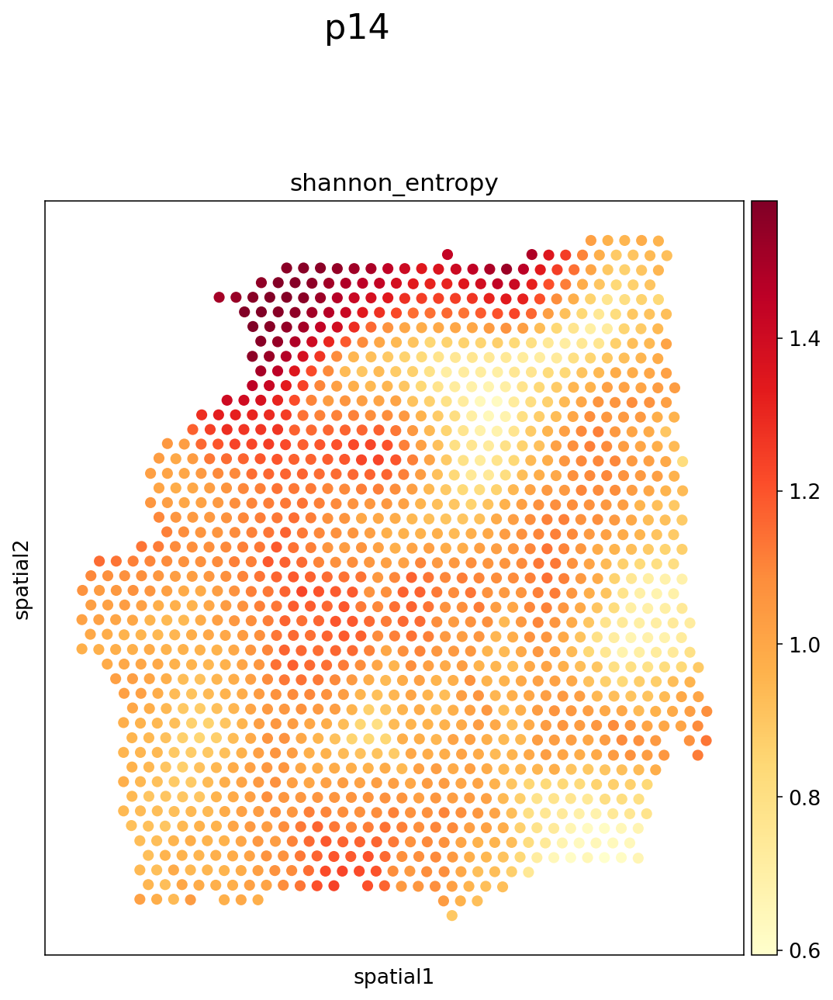

In [9]:
for sample, an in dict_samples.items():
    print(sample)
    deconv_res_path = os.path.join(here,"AVGUSTINOVA_*/st_analysis/4-annotation/*/R_objects_*/4.2.1-norm_weights_p*_l1.csv")
    l = [path for path in glob.glob(deconv_res_path) if sample in path]
    df_l1 = pd.read_csv(l[0], index_col=0)
    
    df_l1 = df_l1.loc[df_l1.index.intersection(dict_samples[sample].obs_names)]
    df_l1 = df_l1.reindex(an.obs_names, fill_value=0)

    an.obsm["X_deconv"] = df_l1
    an = compute_shannon_entropy(an, radius=100)
    sc.pl.spatial(an, color=["shannon_entropy"], 
                 cmap="YlOrRd", img_key=None, show=False)

    plt.suptitle(sample, fontsize=20,y=1.10)  
    plt.show()

#### Shannon-entropy 

In [10]:
# Collect all scores into one dataframe
df_scores = []
for sample, an in dict_samples.items():
    df_tmp = an.obs[['shannon_entropy']].copy()
    df_tmp['sample'] = sample
    df_scores.append(df_tmp)
df_scores = pd.concat(df_scores)

# --- Normalize entropy to [0,1]
n_cell_types = 3  # immune, tumor, stromal
df_scores['entropy_norm'] = df_scores['shannon_entropy'] / np.log(n_cell_types)

# Clip in case of floating point errors
df_scores['entropy_norm'] = df_scores['entropy_norm'].clip(0, 1)

In [11]:
df_summary = (
    df_scores
    .groupby('sample')[['entropy_norm']]
    .median()
    .reset_index()
)

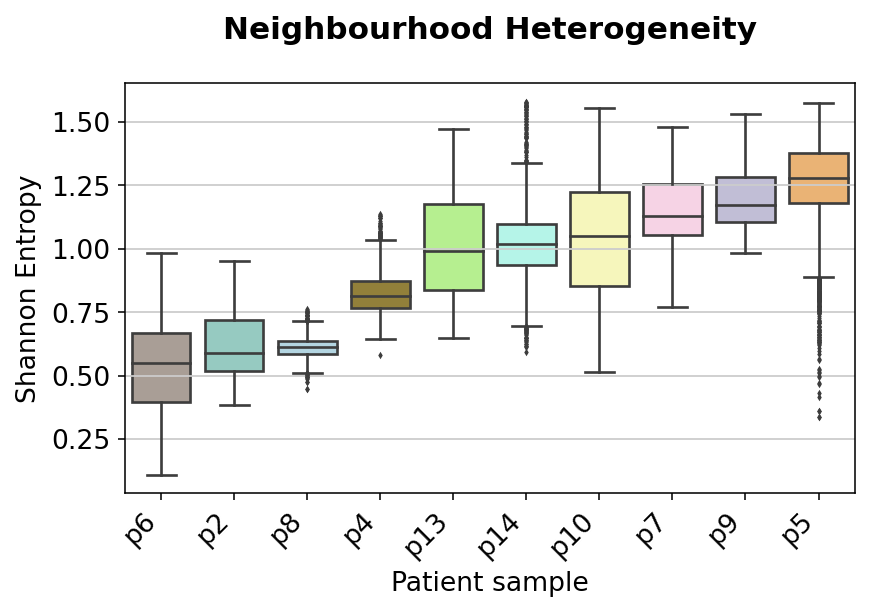

In [12]:
median_order = (
    df_scores.groupby('sample')['shannon_entropy']
    .median()
    .sort_values()
    .index
)

# --- Make boxplot
plt.figure(figsize=(5.5, 4))
sns.boxplot(
    data=df_scores,
    x='sample',
    y='shannon_entropy',
    order=median_order,
    palette=[colors_donors[s] for s in median_order] if 'colors_donors' in locals() else 'Set2',
    fliersize=1,  # smaller outliers
    linewidth=1.2,
    width=0.8
)

plt.title("Neighbourhood Heterogeneity", fontweight='bold', fontsize=14,pad=20)
plt.ylabel("Shannon Entropy", fontsize=12)
plt.xlabel("Patient sample", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.savefig(os.path.join(path_to_figures,'entropy_boxplot.svg'), dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()

### Niche Analysis

In [13]:
spot_features = []
for sample, an in dict_samples.items():
    df = pd.DataFrame(an.obsm['X_deconv'], index=an.obs_names)
    df['shannon_entropy'] = an.obs['shannon_entropy']
    df['sample'] = sample
    spot_features.append(df)

df_all = pd.concat(spot_features)
df_all = df_all.fillna(0)

In [14]:
scaler = StandardScaler()
X = scaler.fit_transform(df_all[['Immune', 'Tumor', 'Other stromal','shannon_entropy']])

In [15]:
k = 5
km = KMeans(n_clusters=k, random_state=0)
df_all['niche'] = km.fit_predict(X)

/home/groups/singlecell/isentis/conda_envs/ines_spatial_py/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


In [16]:
niche_summary = df_all.groupby('niche')[['Immune', 'Tumor', 'Other stromal','shannon_entropy']].mean()
pd.DataFrame(niche_summary, index=[2,0,3,1,4]).round(3)

,Immune,Tumor,Other stromal,shannon_entropy
2,0.117,0.870,0.013,0.656
0,0.089,0.744,0.167,1.106
3,0.128,0.427,0.444,1.246
1,0.309,0.626,0.065,1.175
4,0.503,0.383,0.113,1.320


In [17]:
niche_counts = df_all.groupby(['sample', 'niche']).size().unstack(fill_value=0)
niche_props = niche_counts.div(niche_counts.sum(axis=1), axis=0)

In [18]:
niche_props = niche_props.reindex(median_order)
niche_props = niche_props[[2,0,3,1,4]]

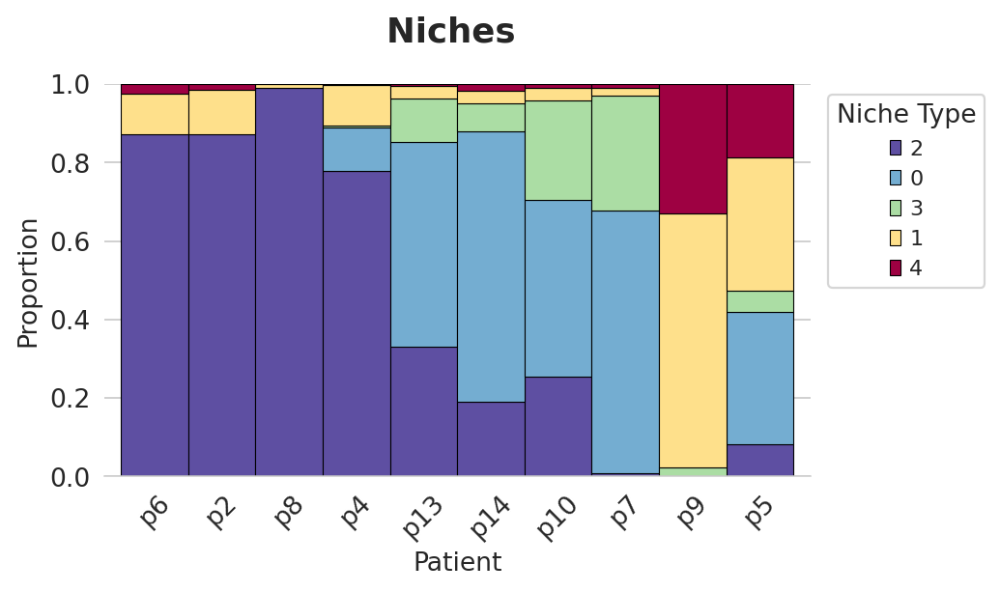

In [19]:
sns.set_style("whitegrid") 

fig, ax = plt.subplots(figsize=(7, 4)) # Slightly larger figure for better readability

niche_props.plot(
    kind='bar', 
    stacked=True, 
    ax=ax, 
    #color=sns.color_palette("flare", n_colors=niche_props.shape[1]), 
    color = ['#5e4fa2','#74add1','#abdda4','#fee08b','#9e0142'],
    edgecolor='black', 
    linewidth=0.5,    
    width = 1
)

ax.set_title(
    "Niches ", 
    fontsize=16, 
    fontweight='bold', 
    pad=20  
)
ax.set_xlabel("Patient", fontsize=12)
ax.set_ylabel("Proportion", fontsize=12)

plt.xticks(rotation=45, ha='center')
ax.set_ylim(0, 1) 

ax.legend(
    bbox_to_anchor=(1.01, 1), 
    loc='upper left', 
    title='Niche Type', 
    frameon=True,      
    fontsize='small'
)

plt.tight_layout(rect=[0, 0, 0.95, 1]) 
sns.despine(left=True)
plt.savefig(os.path.join(path_to_figures,'niche_barplot.svg'), dpi=300, bbox_inches='tight')
plt.show()

In [20]:
niche = {
    0: '#74add1',  
    1: '#fee08b',  
    2: '#5e4fa2',
    3: '#abdda4',   
    4: '#9e0142', 
}

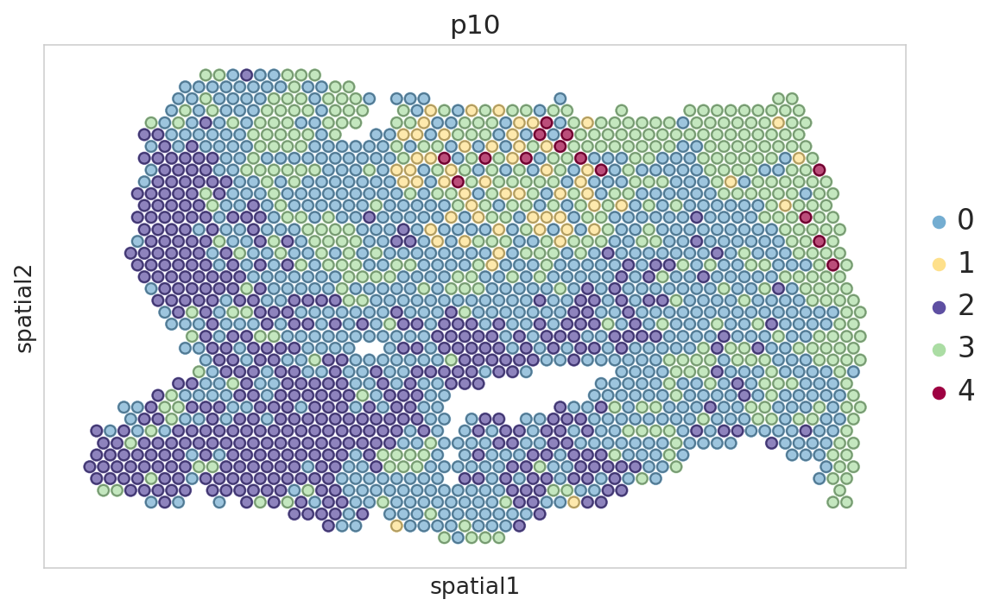

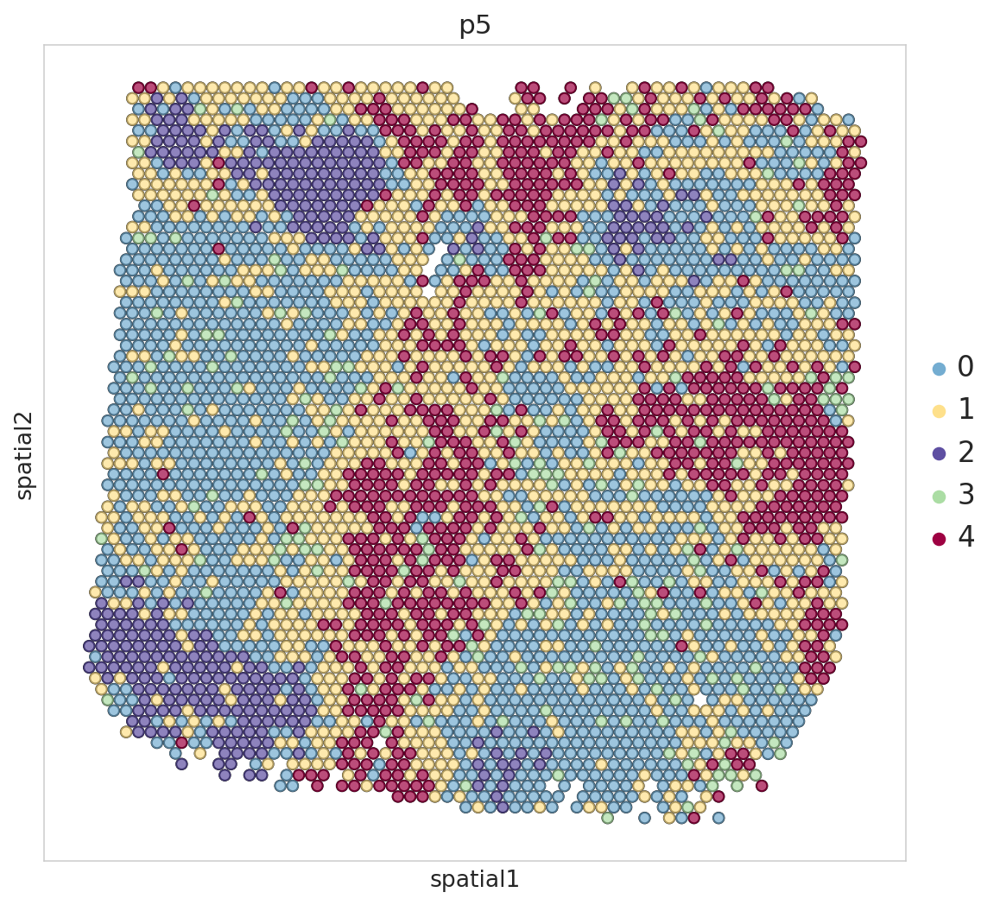

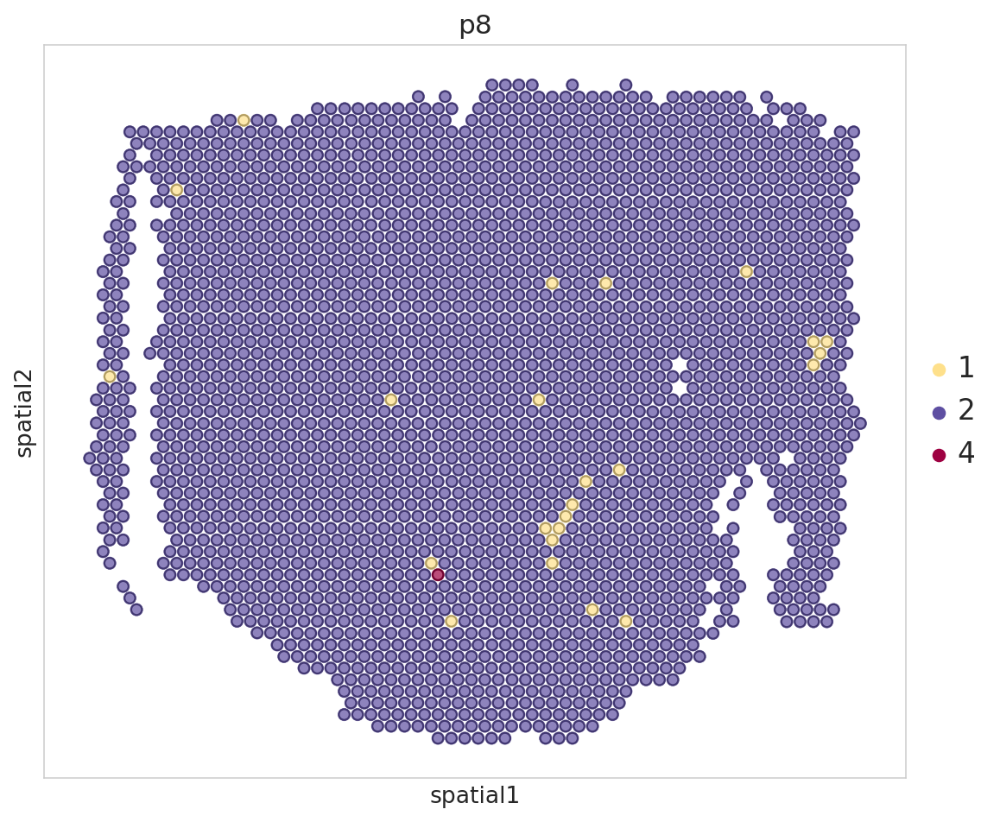

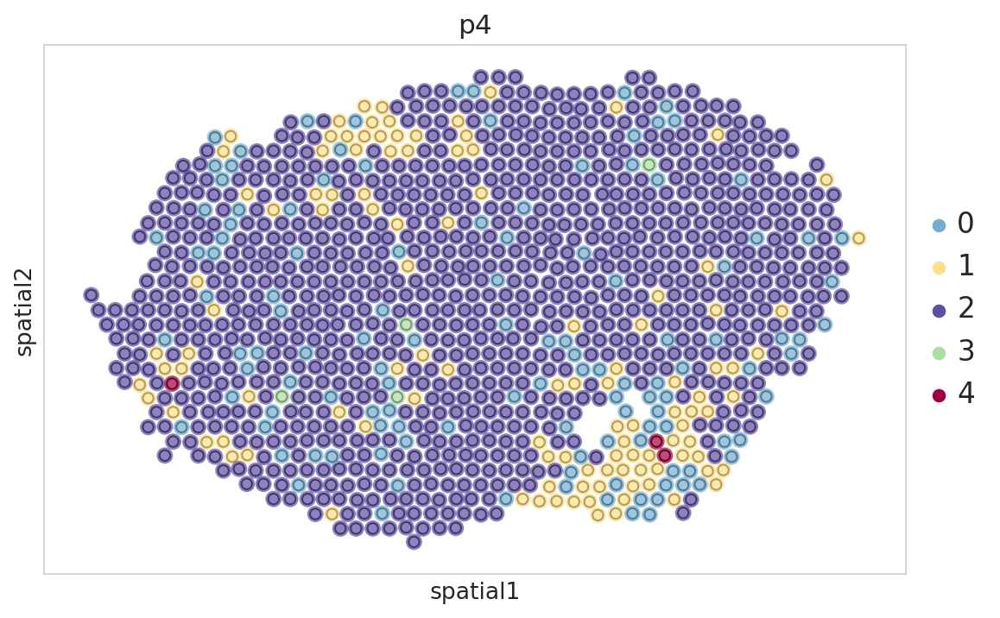

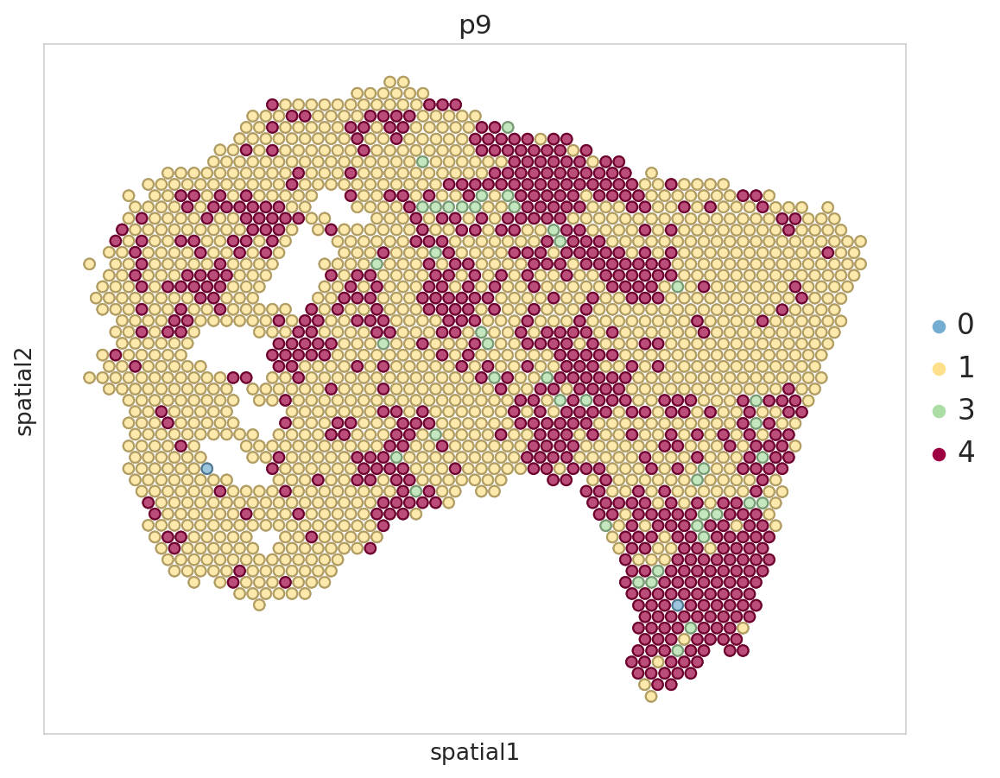

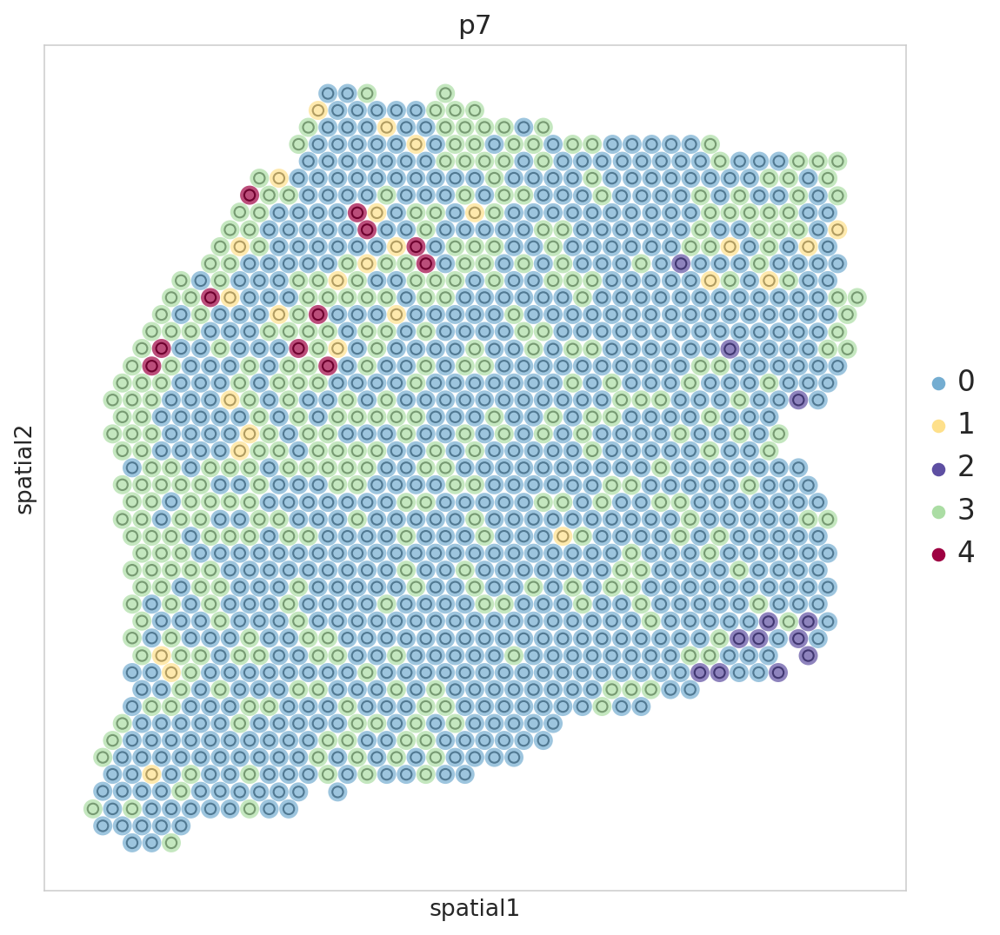

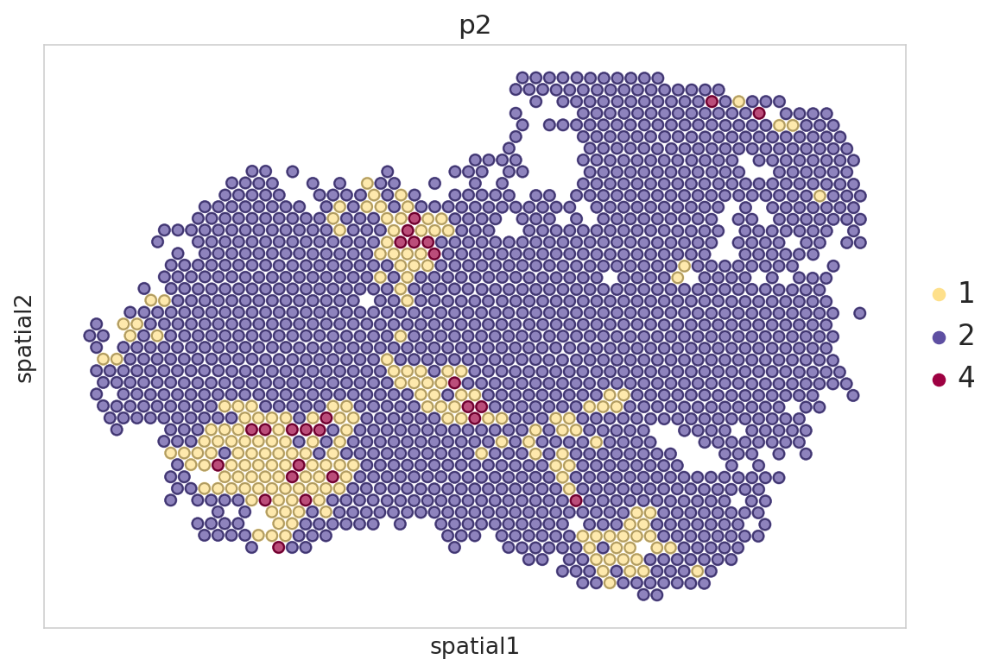

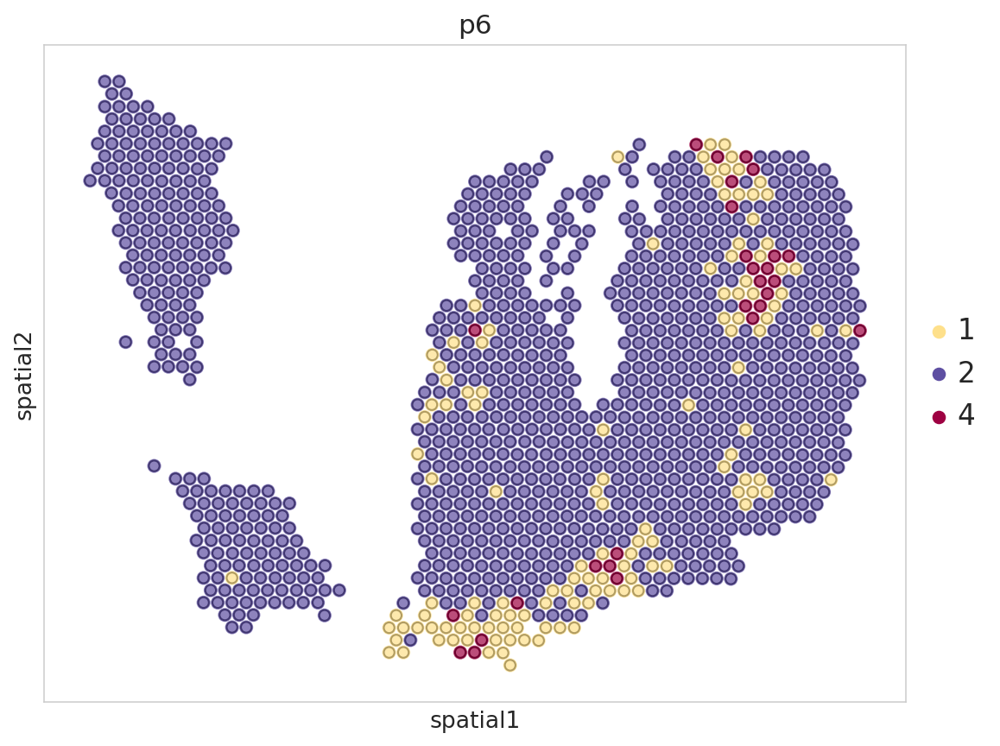

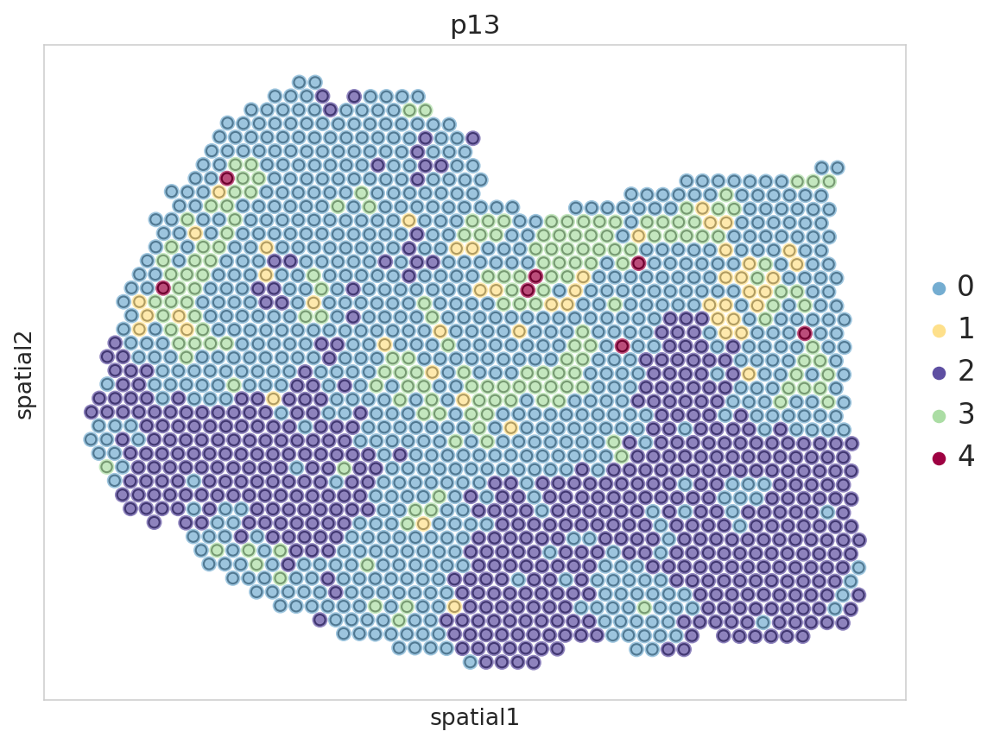

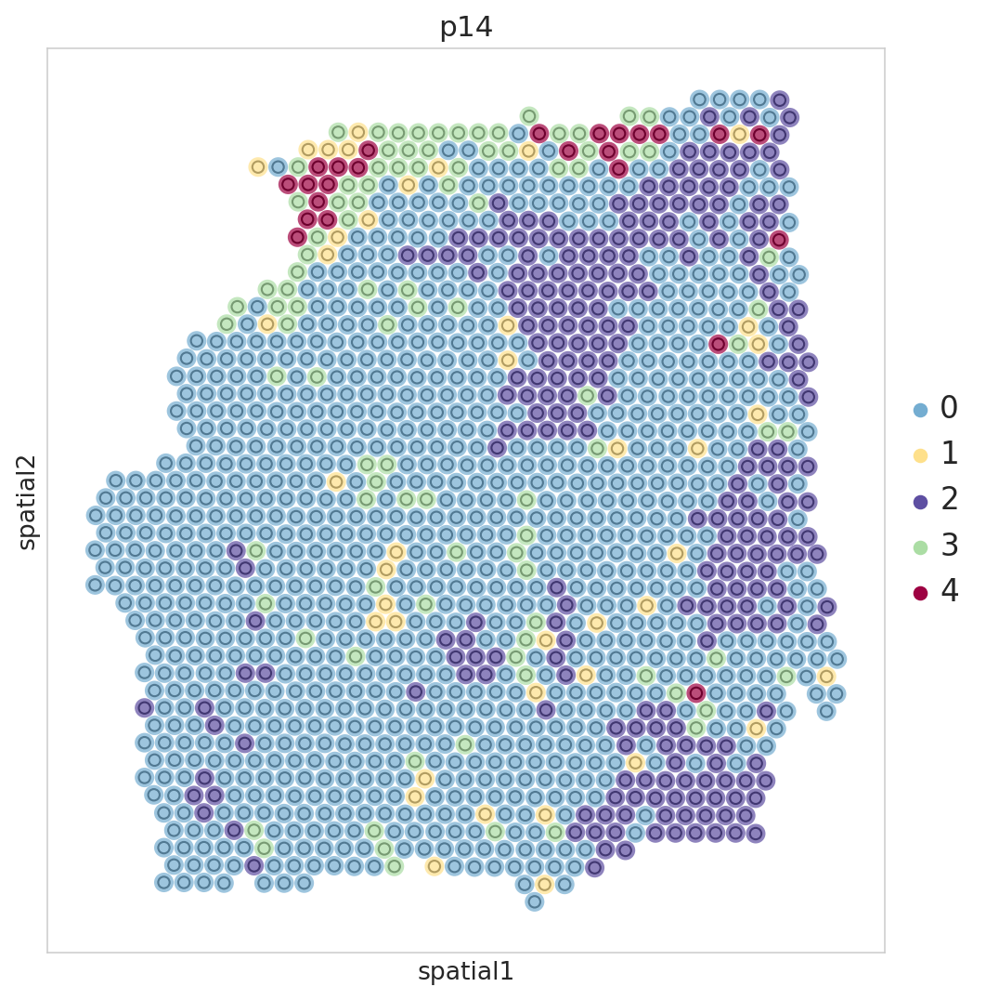

In [27]:
for sample, an in dict_samples.items():
    an.obs['niche'] = df_all.loc[an.obs_names, 'niche']
    an.obs['niche'] = an.obs['niche'].astype('category') 
    sc.pl.spatial(an, color='niche', img_key=None, size=1.5, palette=niche, 
                  add_outline = True,outline_width=(0.5,0.7),
                  title=sample,save="_"+sample+"_niche.svg")

In [22]:
df_all[["sample", "niche"]].to_csv(os.path.join(here, "AVGUSTINOVA_01_06_09_15","all_niches.csv"))